# P5 — Deteksi Tepi (Bagian 1 dan 2)
Nama: Prima Pratama Putra · NIM 2330511022 · Kelas 7A · **SEED = 1022**

- Kanal utama: **R** (KB tertinggi pada Evaluasi P1–P4).
- Praproses: `praproses(img, PARAM)` dengan `PARAM = hasil/param_praproses.json`. Berkas ini berformat adaptif (`dasar`, `per_kondisi`, `ambang`), dan `praproses()` meneruskannya ke `praproses_adaptif()`. Hasilnya: terang → gamma 1,6; bayangan → CLAHE clip 1,0; kondisi lain hanya median 3.

## Bagian 1. Gradien Citra dan Operator Tepi
### Langkah 1.1 Lembar hitung manual (dicek dengan kode)
Lembar hitung dikerjakan dengan tangan (lampiran laporan). Sel ini hanya memeriksa angkanya. Kernel diterapkan sebagai **korelasi**, sama seperti `cv2.filter2D`.

In [1]:
import numpy as np, cv2
A = np.array([[52, 55, 180], [50, 58, 185], [54, 60, 190]], np.float32)
SOBEL_X = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], np.float32)
PREWITT_X = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], np.float32)
LAPLACE = np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]], np.float32)

for nama, kx in [("Sobel", SOBEL_X), ("Prewitt", PREWITT_X)]:
    gx, gy = float((A * kx).sum()), float((A * kx.T).sum())
    # pemeriksaan: cv2.filter2D (korelasi) di piksel tengah harus sama
    assert gx == cv2.filter2D(A, -1, kx)[1, 1] and gy == cv2.filter2D(A, -1, kx.T)[1, 1]
    print(f"{nama:8s} Gx = {gx:.0f}, Gy = {gy:.0f}, |G| = {np.hypot(gx, gy):.2f}, "
          f"|Gx|+|Gy| = {abs(gx) + abs(gy):.0f}, theta = {np.degrees(np.arctan2(gy, gx)):.2f} derajat")
print("Laplacian piksel tengah =", float((A * LAPLACE).sum()))

Sobel    Gx = 534, Gy = 22, |G| = 534.45, |Gx|+|Gy| = 556, theta = 2.36 derajat
Prewitt  Gx = 399, Gy = 17, |G| = 399.36, |Gx|+|Gy| = 416, theta = 2.44 derajat
Laplacian piksel tengah = 118.0


Hasil sama dengan hitungan tangan: Sobel |G| = 534,45 (θ = 2,36°), Prewitt |G| = 399,36 (θ = 2,44°), Laplacian = +118.

### Langkah 1.2 Persiapan dan gradien Sobel
**Kode 1.1** Persiapan: modul, data, praproses, dan tepi acuan

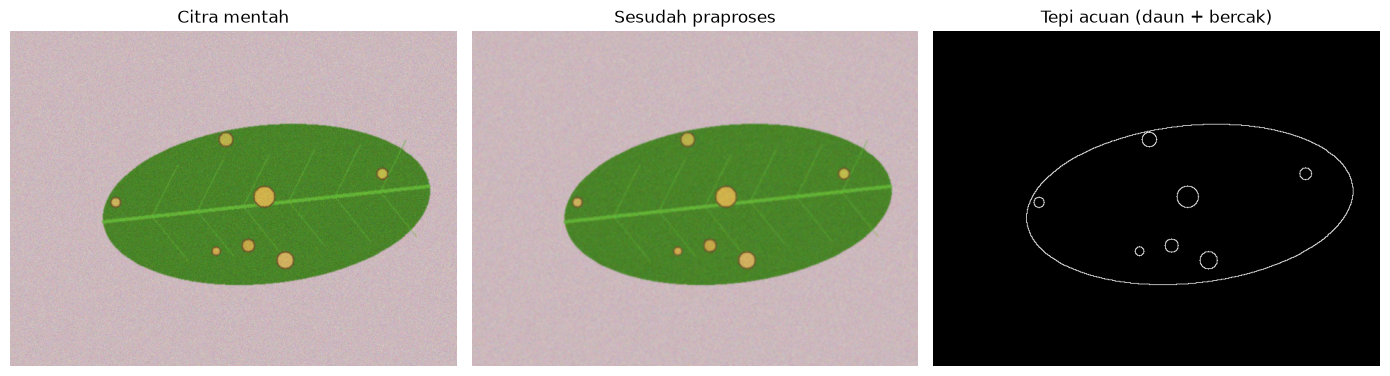

In [2]:
import sys, json, time
sys.path.append("../src")
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil
from praproses import praproses
from utils_tepi import tepi_acuan, skor_tepi, iou, mask_daun_awal, bercak_awal

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)
PARAM = json.load(open("../hasil/param_praproses.json"))   # hasil Evaluasi P1-P4
label = pd.read_csv("../data/sintetis/label.csv")
URUT = ["normal", "gelap", "terang", "kontras_rendah", "bayangan"]

def muat(nama):
    img = baca(f"../data/sintetis/citra/{nama}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
    return img, md, mb

def simpan(nama):
    plt.savefig(f"../hasil/{nama}", dpi=120, bbox_inches="tight")

img, md, mb = muat("teh_041.png")
pra = praproses(img, PARAM)
acuan = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
tampil([img, pra, acuan], ["Citra mentah", "Sesudah praproses", "Tepi acuan (daun + bercak)"])
simpan("p5_input_acuan.png"); plt.show()

**Kode 1.2** Gradien Sobel manual: Gx, Gy, magnitudo, dan arah

selisih maks gx manual vs cv2.Sobel: 0.0
magnitudo maks: 463.8


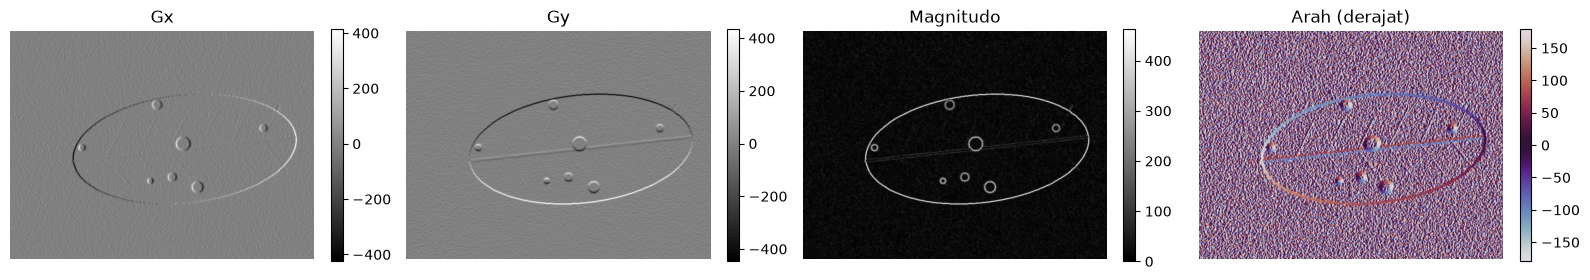

In [3]:
g = pra[:, :, 2].astype(np.float32)          # kanal R hasil praproses
kx = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], np.float32)
ky = kx.T
gx = cv2.filter2D(g, cv2.CV_32F, kx)         # turunan arah x (tepi vertikal)
gy = cv2.filter2D(g, cv2.CV_32F, ky)         # turunan arah y (tepi horizontal)
mag = np.sqrt(gx ** 2 + gy ** 2)
arah = np.degrees(np.arctan2(gy, gx))

# bandingkan dengan fungsi pustaka
gx_cv = cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3)
print("selisih maks gx manual vs cv2.Sobel:", np.abs(gx - gx_cv).max())
print("magnitudo maks:", mag.max().round(1))

plt.figure(figsize=(16, 3.6))
for i, (c_, jd) in enumerate([(gx, "Gx"), (gy, "Gy"), (mag, "Magnitudo"), (arah, "Arah (derajat)")]):
    plt.subplot(1, 4, i + 1); plt.imshow(c_, cmap="twilight" if i == 3 else "gray")
    plt.title(jd); plt.axis("off"); plt.colorbar(fraction=0.035)
plt.tight_layout(); simpan("p5_sobel_manual.png"); plt.show()

**Bukti P1.1: arah gradien tegak lurus tepi.** Pada setiap piksel tepi bercak acuan, arah gradien dibandingkan dengan arah radial (dari pusat bercak ke piksel itu). Bercak bundar, jadi tepinya menyinggung lingkaran dan arah tegak lurus tepi sama dengan arah radial. Di kanal R bercak lebih terang daripada daun, sehingga gradien (gelap → terang) seharusnya menunjuk **ke dalam** bercak, berlawanan dengan arah radial (selisih ±180°).

564 piksel tepi bercak pada 7 komponen
median |arah gradien - arah radial| = 175.9 derajat
porsi dengan selisih > 160 derajat (menunjuk ke dalam bercak) = 0.996


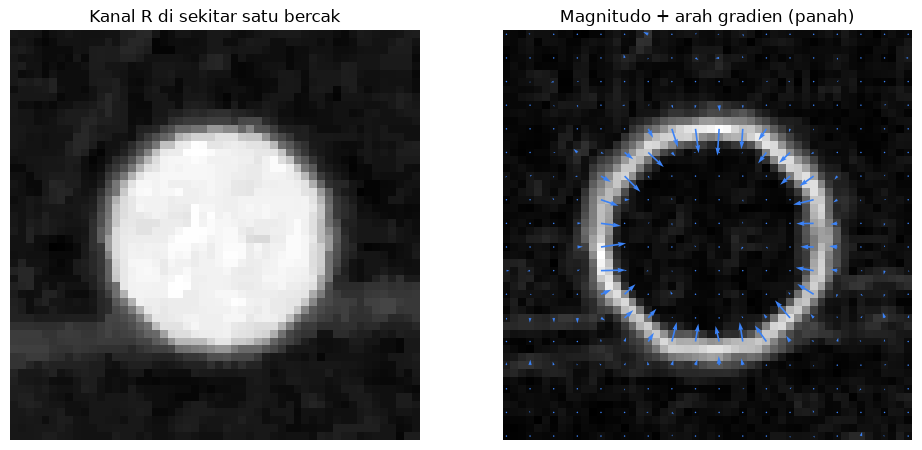

In [4]:
n, lab, st, pusat = cv2.connectedComponentsWithStats((mb > 0).astype(np.uint8))
ys, xs = np.nonzero(tepi_acuan(mb))
k = lab[ys, xs]
radial = np.degrees(np.arctan2(ys - pusat[k, 1], xs - pusat[k, 0]))
selisih = np.abs((arah[ys, xs] - radial + 180) % 360 - 180)   # 0..180 derajat
print(f"{len(xs)} piksel tepi bercak pada {n - 1} komponen")
print(f"median |arah gradien - arah radial| = {np.median(selisih):.1f} derajat")
print(f"porsi dengan selisih > 160 derajat (menunjuk ke dalam bercak) = {(selisih > 160).mean():.3f}")

# zoom satu bercak besar dengan panah gradien
i = 1 + np.argmax(st[1:, cv2.CC_STAT_AREA])
cx, cy = pusat[i].astype(int); r = 26
sl = (slice(cy - r, cy + r), slice(cx - r, cx + r))
yy, xx = np.mgrid[0:2 * r:3, 0:2 * r:3]
plt.figure(figsize=(10, 4.6))
plt.subplot(1, 2, 1); plt.imshow(g[sl], cmap="gray"); plt.title("Kanal R di sekitar satu bercak"); plt.axis("off")
plt.subplot(1, 2, 2); plt.imshow(mag[sl], cmap="gray")
plt.quiver(xx, yy, gx[sl][::3, ::3], -gy[sl][::3, ::3], color="#3b82f6", scale=6000, width=0.004)
plt.title("Magnitudo + arah gradien (panah)"); plt.axis("off")
plt.tight_layout(); simpan("p5_arah_bercak.png"); plt.show()

**Temuan:** 99,6% piksel tepi bercak punya arah gradien yang berlawanan dengan arah radial (median selisih 175,9°). Gradien selalu tegak lurus tepi dan menunjuk ke sisi yang lebih terang (bercak). Karena itu warna pada panel arah Kode 1.2 berputar mengelilingi setiap bercak.

### Langkah 1.3 Empat operator pada satu citra
**Kode 1.3** Fungsi Sobel, Prewitt, LoG, dan Canny serta perbandingannya

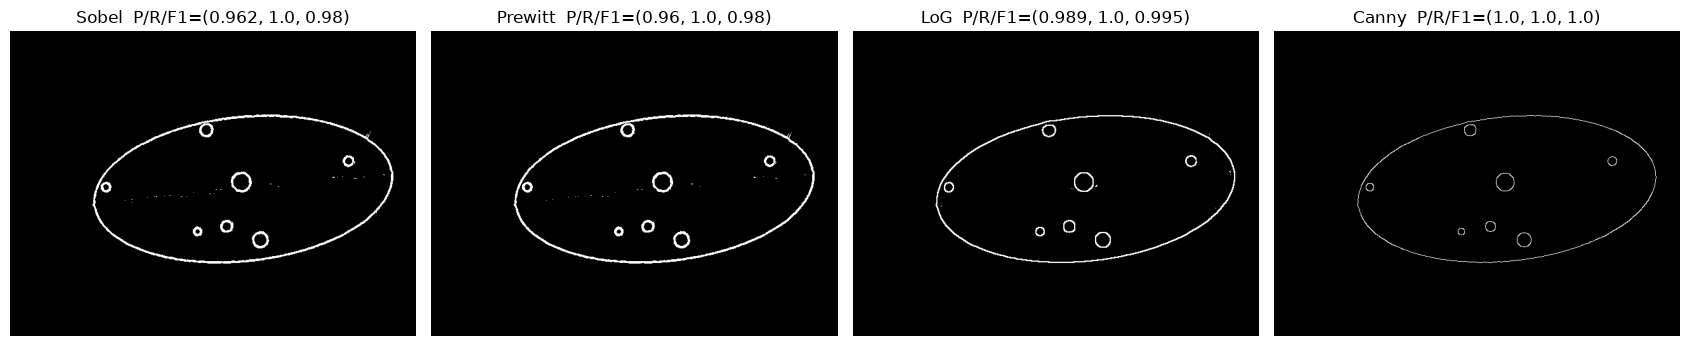

In [5]:
def tepi_sobel(g, T=100):
    g = g.astype(np.float32)
    m = np.hypot(cv2.Sobel(g, cv2.CV_32F, 1, 0), cv2.Sobel(g, cv2.CV_32F, 0, 1))
    return ((m > T) * 255).astype(np.uint8)

def tepi_prewitt(g, T=75):
    kx = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], np.float32)
    g = g.astype(np.float32)
    m = np.hypot(cv2.filter2D(g, -1, kx), cv2.filter2D(g, -1, kx.T))
    return ((m > T) * 255).astype(np.uint8)

def tepi_log(g, sigma=3.0, frac=0.2):
    # Laplacian of Gaussian: tepi = perlintasan nol yang cukup kuat.
    L = cv2.Laplacian(cv2.GaussianBlur(g.astype(np.float32), (0, 0), sigma), cv2.CV_32F)
    mn, mx = cv2.erode(L, np.ones((3, 3))), cv2.dilate(L, np.ones((3, 3)))
    return (((mn < 0) & (mx > 0) & (mx - mn > frac * np.abs(L).max())) * 255).astype(np.uint8)

def tepi_canny(g, lo=30, hi=90, sigma=2.0):
    if sigma > 0:
        g = cv2.GaussianBlur(g, (0, 0), sigma)
    return cv2.Canny(g, lo, hi)

metode = {"Sobel": tepi_sobel, "Prewitt": tepi_prewitt, "LoG": tepi_log, "Canny": tepi_canny}
g = pra[:, :, 2]
hasil = {nm: f(g) for nm, f in metode.items()}
tampil(list(hasil.values()), [f"{nm}  P/R/F1={skor_tepi(e, acuan)}" for nm, e in hasil.items()],
       ukuran=(17, 3.6))
simpan("p5_empat_operator.png"); plt.show()

**Bukti P1.2: Sobel vs Prewitt.** Rasio magnitudo Sobel/Prewitt dihitung di piksel tepi acuan. Untuk tepi tangga ideal, rasionya 4/3 karena jumlah bobot positif Sobel 4 (1+2+1), sedangkan Prewitt 3 (1+1+1). Lalu Prewitt diuji dengan ambang yang sama dengan Sobel (T = 100).

In [6]:
gf = g.astype(np.float32)
m_sob = np.hypot(cv2.Sobel(gf, cv2.CV_32F, 1, 0), cv2.Sobel(gf, cv2.CV_32F, 0, 1))
m_pre = np.hypot(cv2.filter2D(gf, -1, PREWITT_X), cv2.filter2D(gf, -1, PREWITT_X.T))
t = (acuan > 0) & (m_pre > 30)
print(f"median rasio Sobel/Prewitt di tepi acuan = {np.median(m_sob[t] / m_pre[t]):.3f} (teori 4/3 = 1.333)")
for nm, e in [("Sobel T=100", tepi_sobel(g, 100)), ("Prewitt T=75", tepi_prewitt(g, 75)),
              ("Prewitt T=100", tepi_prewitt(g, 100)), ("Sobel T=75", tepi_sobel(g, 75))]:
    print(f"{nm:14s} piksel tepi = {int((e > 0).sum()):6d}  P/R/F1 = {skor_tepi(e, acuan)}")

median rasio Sobel/Prewitt di tepi acuan = 1.339 (teori 4/3 = 1.333)
Sobel T=100    piksel tepi =   5559  P/R/F1 = (0.962, 1.0, 0.98)
Prewitt T=75   piksel tepi =   5601  P/R/F1 = (0.96, 1.0, 0.98)
Prewitt T=100  piksel tepi =   4603  P/R/F1 = (0.985, 1.0, 0.993)
Sobel T=75     piksel tepi =   6807  P/R/F1 = (0.866, 1.0, 0.928)


**Temuan:** rasio Sobel/Prewitt di tepi 1,339 ≈ 4/3. Ambang pada petunjuk sudah disetarakan (Prewitt 75 = Sobel 100 × 3/4), sehingga jumlah piksel tepinya hampir sama (5.559 vs 5.601). Bila ambang yang sama dipakai, Prewitt T = 100 setara Sobel T ≈ 133 (lebih ketat), sedangkan Sobel T = 75 setara Prewitt T ≈ 56 (lebih longgar, presisi turun ke 0,866).

### Langkah 1.4 Perbandingan menyeluruh
**Kode 1.4** Tabel presisi, recall, dan F1 tepi (40 citra berbercak × mentah/praproses × Gray/R × 4 operator)

In [7]:
baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
    for sumber, im in [("mentah", img), ("praproses", praproses(img, PARAM))]:
        for kanal, g in [("Gray", cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)), ("R", im[:, :, 2])]:
            for nm, f in metode.items():
                p, r, f1 = skor_tepi(f(g), ac)
                baris.append([d.kondisi_cahaya, sumber, kanal, nm, p, r, f1])
tabel_tepi = pd.DataFrame(baris, columns=["kondisi", "sumber", "kanal", "metode", "P", "R", "F1"])
ringkas = tabel_tepi.groupby(["sumber", "kanal", "metode"])[["P", "R", "F1"]].mean().round(3)
print(ringkas)
tabel_tepi.to_csv("../hasil/p5_tabel_tepi.csv", index=False)

                             P      R     F1
sumber    kanal metode                      
mentah    Gray  Canny    0.794  0.768  0.779
                LoG      0.628  0.997  0.759
                Prewitt  0.795  0.969  0.865
                Sobel    0.761  0.974  0.843
          R     Canny    0.988  0.982  0.984
                LoG      0.907  0.997  0.942
                Prewitt  0.555  0.997  0.664
                Sobel    0.487  0.997  0.601
praproses Gray  Canny    0.729  0.757  0.740
                LoG      0.621  0.998  0.754
                Prewitt  0.875  0.856  0.815
                Sobel    0.869  0.868  0.827
          R     Canny    0.987  0.977  0.981
                LoG      0.913  0.997  0.944
                Prewitt  0.890  0.987  0.929
                Sobel    0.876  0.989  0.919


**Tabel 6** (rerata F1, susunan sesuai format petunjuk)

In [8]:
tabel6 = ringkas["F1"].unstack(["sumber", "kanal"]).loc[["Sobel", "Prewitt", "LoG", "Canny"]]
tabel6 = tabel6[[("mentah", "Gray"), ("mentah", "R"), ("praproses", "Gray"), ("praproses", "R")]]
tabel6.to_csv("../hasil/p5_tabel6.csv")
tabel6

sumber  mentah        praproses       
kanal     Gray      R      Gray      R
metode                                
Sobel    0.843  0.601     0.827  0.919
Prewitt  0.865  0.664     0.815  0.929
LoG      0.759  0.942     0.754  0.944
Canny    0.779  0.984     0.740  0.981

**Temuan Tabel 6:** sesudah praproses, kanal R lebih baik daripada Gray untuk keempat operator (Canny 0,981 vs 0,740; Sobel 0,919 vs 0,827). Pada citra mentah, Sobel dan Prewitt kanal R rendah (0,601 dan 0,664) karena derau sensor ikut melewati ambang. Canny dan LoG tidak banyak terpengaruh karena sudah punya penghalusan Gaussian sendiri.

**Bukti P1.4:** perubahan P, R, dan F1 akibat praproses (praproses − mentah), rerata 40 citra, lalu dirinci per kondisi untuk kanal R.

In [9]:
piv = tabel_tepi.pivot_table(index=["kanal", "metode"], columns="sumber", values=["P", "R", "F1"])
delta = pd.DataFrame({u: piv[(u, "praproses")] - piv[(u, "mentah")] for u in ["P", "R", "F1"]}).round(3)
print(delta)
for kanal in ["Gray", "R"]:
    pk = tabel_tepi[tabel_tepi.kanal == kanal].pivot_table(index=["metode", "kondisi"], columns="sumber", values=["P", "R"])
    dk = pd.DataFrame({u: pk[(u, "praproses")] - pk[(u, "mentah")] for u in ["P", "R"]}).round(3)
    print(f"\nPerubahan per kondisi (kanal {kanal}):")
    print(dk.unstack("kondisi")[[(u, k) for u in ["P", "R"] for k in URUT]])

                   P      R     F1
kanal metode                      
Gray  Canny   -0.065 -0.011 -0.039
      LoG     -0.007  0.001 -0.005
      Prewitt  0.080 -0.112 -0.050
      Sobel    0.108 -0.105 -0.016
R     Canny   -0.001 -0.005 -0.003
      LoG      0.005  0.000  0.003
      Prewitt  0.335 -0.010  0.264
      Sobel    0.389 -0.008  0.318

Perubahan per kondisi (kanal Gray):
             P                                            R                                      
kondisi normal  gelap terang kontras_rendah bayangan normal  gelap terang kontras_rendah bayangan
metode                                                                                           
Canny   -0.017 -0.002 -0.017         -0.121   -0.167 -0.004 -0.004  0.007         -0.074    0.020
LoG      0.014  0.015  0.004          0.000   -0.067 -0.000  0.000  0.000          0.000    0.003
Prewitt  0.152  0.095  0.070          0.105   -0.022  0.000 -0.000  0.000         -0.563    0.001
Sobel    0.175  0.108  0.

**Temuan:**
- Median 3 menaikkan presisi Sobel/Prewitt kanal R (+0,39/+0,34) karena derau diredam.
- Praproses menurunkan recall Sobel/Prewitt kanal Gray pada kontras rendah (−0,53/−0,56) dan sedikit pada kanal R (−0,04/−0,05). Median ikut melandaikan tepi yang sudah lemah sehingga magnitudonya jatuh di bawah T.
- Canny kanal Gray kontras rendah sudah gagal pada citra mentah (F1 0,092; hanya 1 dari 8 citra punya tepi) dan sesudah median tidak menemukan tepi sama sekali, sehingga P turun −0,12.
- Pada kondisi bayangan, presisi Canny kanal Gray turun −0,17 karena CLAHE ikut menguatkan tulang daun yang di Gray kontrasnya tinggi.

**Bukti P1.5: kepekaan LoG terhadap sigma dan ambang perlintasan nol.** `frac = 0` berarti semua perlintasan nol diterima tanpa ambang (kanal R, sesudah praproses).

In [10]:
data40 = [(d.kelas, d.kondisi_cahaya, *muat(d.nama_file)) for _, d in label[label.kelas != "sehat"].iterrows()]
pra40 = [(kl, kd, praproses(im, PARAM), md, mb) for kl, kd, im, md, mb in data40]
baris = []
for kl, kd, p_, md, mb in pra40:
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
    for s in [1.0, 2.0, 3.0, 4.0]:
        for fr in [0.0, 0.05, 0.1, 0.2, 0.3]:
            e = tepi_log(p_[:, :, 2], s, fr)
            baris.append([s, fr, *skor_tepi(e, ac), int((e > 0).sum())])
log_sw = pd.DataFrame(baris, columns=["sigma", "frac", "P", "R", "F1", "piksel_tepi"])
log_ring = log_sw.groupby(["sigma", "frac"]).mean().round(3)
log_ring.to_csv("../hasil/p5_log_sweep.csv")
print(log_ring.unstack("frac")[["P", "R", "F1"]])

           P                                  R                                 F1                            
frac    0.00   0.05   0.10   0.20   0.30   0.00   0.05   0.10   0.20   0.30   0.00   0.05   0.10   0.20   0.30
sigma                                                                                                         
1.0    0.014  0.015  0.018  0.062  0.184  1.000  1.000  1.000  1.000  0.999  0.028  0.029  0.035  0.104  0.272
2.0    0.017  0.027  0.110  0.465  0.749  0.999  0.999  0.999  0.999  0.998  0.034  0.051  0.173  0.572  0.825
3.0    0.024  0.197  0.562  0.913  0.980  0.998  0.998  0.998  0.997  0.982  0.048  0.287  0.672  0.944  0.980
4.0    0.032  0.491  0.873  0.986  0.993  0.997  0.997  0.997  0.991  0.858  0.062  0.611  0.923  0.988  0.907


**Temuan:** tanpa ambang (frac = 0) LoG menerima setiap perlintasan nol, termasuk yang ditimbulkan derau: presisi hanya 0,014–0,032 walaupun recall ≈ 1. Menaikkan frac dan sigma menyaring perlintasan lemah: F1 naik sampai 0,980 (sigma 3, frac 0,3) dan 0,988 (sigma 4, frac 0,2). Sigma 4 dengan frac 0,3 mulai menghilangkan tepi (recall 0,858).

### Langkah 1.5 Grafik F1 per kondisi cahaya (kanal R, sesudah praproses)

metode          Sobel  Prewitt    LoG  Canny
kondisi                                     
normal          0.972    0.971  0.977  0.995
gelap           0.947    0.942  0.980  0.982
terang          0.850    0.881  0.974  0.988
kontras_rendah  0.971    0.968  0.803  0.943
bayangan        0.855    0.881  0.987  0.998


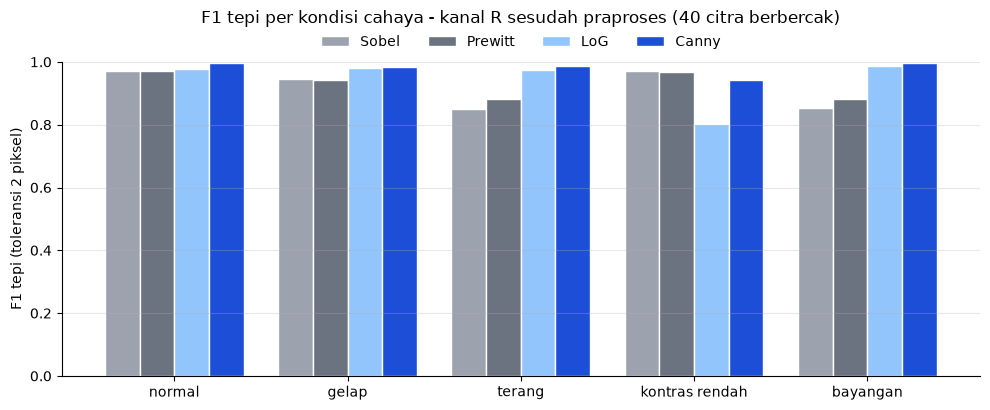

In [11]:
f1k = (tabel_tepi[(tabel_tepi.sumber == "praproses") & (tabel_tepi.kanal == "R")]
       .pivot_table(index="kondisi", columns="metode", values="F1").loc[URUT, ["Sobel", "Prewitt", "LoG", "Canny"]])
print(f1k.round(3))
warna = ["#9ca3af", "#6b7280", "#93c5fd", "#1d4ed8"]
ax = f1k.plot(kind="bar", figsize=(10, 4.2), color=warna, width=0.8, edgecolor="white")
ax.set_ylabel("F1 tepi (toleransi 2 piksel)"); ax.set_xlabel("")
ax.set_xticklabels([k.replace("_", " ") for k in URUT], rotation=0)
ax.set_ylim(0, 1); ax.set_title("F1 tepi per kondisi cahaya - kanal R sesudah praproses (40 citra berbercak)", pad=28)
ax.legend(ncol=4, loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False); ax.grid(axis="y", alpha=0.3)
for s in ["top", "right"]: ax.spines[s].set_visible(False)
plt.tight_layout(); simpan("p5_f1_kondisi.png"); plt.show()

**Temuan:**
- Canny paling stabil di semua kondisi (0,943–0,998).
- Sobel/Prewitt turun pada terang dan bayangan (0,85–0,88).
- LoG turun pada kontras rendah (0,803; presisi 0,714). Ambang LoG relatif terhadap |L| maksimum, sedangkan pada kontras rendah sinyal tepi menyusut 0,35× tetapi derau tidak, sehingga perlintasan nol akibat derau ikut lolos.

## Bagian 2. Algoritma Canny dan Keputusan Pemakaian Tepi
### Langkah 2.1 Lembar hitung manual (dicek dengan kode)
(a) NMS: arah gradien 0° → bandingkan dengan tetangga kiri-kanan; 90° → atas-bawah. Piksel dipertahankan bila ≥ kedua tetangga itu.
(b) Hysteresis: kuat bila > ambang atas, lemah bila di antara kedua ambang. Piksel lemah dipertahankan hanya bila tersambung ke piksel kuat (langsung atau lewat rantai piksel lemah).

In [12]:
M1 = np.array([[30, 40, 35], [90, 100, 95], [20, 30, 25]])
M2 = np.array([[50, 60, 55], [85, 80, 70], [40, 45, 50]])
def nms(M, sudut):
    tetangga = (int(M[1, 0]), int(M[1, 2])) if sudut == 0 else (int(M[0, 1]), int(M[2, 1]))
    return ("dipertahankan" if M[1, 1] >= max(tetangga) else "ditekan"), tetangga
for nm, M in [("M1", M1), ("M2", M2)]:
    for sd in [0, 90]:
        hasil_, tt = nms(M, sd)
        print(f"{nm} arah {sd:2d} derajat: pusat {M[1, 1]} vs tetangga {tt} -> {hasil_}")

def hysteresis_1d(v, lo, hi):
    v = np.asarray(v); kuat = v > hi; lemah = (v >= lo) & ~kuat
    tepi = kuat.copy(); berubah = True
    while berubah:                       # rambatkan dari piksel kuat lewat piksel lemah
        berubah = False
        for i in np.nonzero(lemah & ~tepi)[0]:
            if (i > 0 and tepi[i - 1]) or (i < len(v) - 1 and tepi[i + 1]):
                tepi[i] = True; berubah = True
    return [int(x) for x in kuat], [int(x) for x in lemah], [int(x) for x in tepi]
baris_ = [20, 60, 120, 80, 40, 90, 30]
k_, l_, t_ = hysteresis_1d(baris_, 50, 100)
print("\nnilai :", baris_); print("kuat  :", k_); print("lemah :", l_); print("tepi  :", t_)

M1 arah  0 derajat: pusat 100 vs tetangga (90, 95) -> dipertahankan
M1 arah 90 derajat: pusat 100 vs tetangga (40, 30) -> dipertahankan
M2 arah  0 derajat: pusat 80 vs tetangga (85, 70) -> ditekan
M2 arah 90 derajat: pusat 80 vs tetangga (60, 45) -> dipertahankan

nilai : [20, 60, 120, 80, 40, 90, 30]
kuat  : [0, 0, 1, 0, 0, 0, 0]
lemah : [0, 1, 0, 1, 0, 1, 0]
tepi  : [0, 1, 1, 1, 0, 0, 0]


Sama dengan hitungan tangan:
- NMS: M1 dipertahankan pada kedua arah; M2 ditekan pada 0° (80 < 85) dan dipertahankan pada 90°.
- Hysteresis: [0, 1, 1, 1, 0, 0, 0]. Piksel 90 lemah tetapi terputus dari piksel kuat oleh piksel 40 (< ambang bawah).

### Langkah 2.2 Pengaruh sigma dan ambang
**Kode 2.1** Eksperimen sigma dan ambang Canny (kanal R sesudah praproses)

In [13]:
baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    g = praproses(img, PARAM)[:, :, 2]
    ad, ab = tepi_acuan(md), tepi_acuan(mb)
    ac = cv2.bitwise_or(ad, ab)
    for sigma in [0, 1.0, 2.0]:
        for lo, hi in [(30, 90), (50, 150), (100, 200)]:
            e = tepi_canny(g, lo, hi, sigma)
            p, r, f1 = skor_tepi(e, ac)
            r_bercak = skor_tepi(e, ab)[1]           # recall khusus tepi bercak
            baris.append([d.kelas, sigma, f"{lo}/{hi}", p, r, f1, r_bercak])
canny = pd.DataFrame(baris, columns=["kelas", "sigma", "ambang", "P", "R", "F1", "R_bercak"])
print(canny.groupby(["sigma", "ambang"])[["P", "R", "F1", "R_bercak"]].mean().round(3))
print(canny.pivot_table(index=["sigma", "ambang"], columns="kelas", values="R_bercak").round(3))

                   P      R     F1  R_bercak
sigma ambang                                
0.0   100/200  0.943  0.961  0.946     0.808
      30/90    0.231  0.996  0.302     0.977
      50/150   0.743  0.994  0.796     0.971
1.0   100/200  0.814  0.805  0.806     0.774
      30/90    0.815  0.995  0.869     0.973
      50/150   0.983  0.961  0.969     0.808
2.0   100/200  0.798  0.776  0.786     0.676
      30/90    0.987  0.977  0.981     0.863
      50/150   0.794  0.794  0.794     0.770
kelas          berat  ringan
sigma ambang                
0.0   100/200  0.852   0.764
      30/90    0.986   0.969
      50/150   0.978   0.965
1.0   100/200  0.790   0.758
      30/90    0.980   0.967
      50/150   0.846   0.770
2.0   100/200  0.693   0.660
      30/90    0.907   0.819
      50/150   0.778   0.762


**Tabel 7** (gabungan dua keluaran di atas)

In [14]:
tabel7 = canny.groupby(["sigma", "ambang"])[["P", "R", "F1"]].mean()
tabel7 = tabel7.join(canny.pivot_table(index=["sigma", "ambang"], columns="kelas", values="R_bercak")
                     .rename(columns={"berat": "R_bercak_berat", "ringan": "R_bercak_ringan"})).round(3)
tabel7.to_csv("../hasil/p5_tabel7_canny.csv")
tabel7

P      R     F1  R_bercak_berat  R_bercak_ringan
sigma ambang                                                       
0.0   100/200  0.943  0.961  0.946           0.852            0.764
      30/90    0.231  0.996  0.302           0.986            0.969
      50/150   0.743  0.994  0.796           0.978            0.965
1.0   100/200  0.814  0.805  0.806           0.790            0.758
      30/90    0.815  0.995  0.869           0.980            0.967
      50/150   0.983  0.961  0.969           0.846            0.770
2.0   100/200  0.798  0.776  0.786           0.693            0.660
      30/90    0.987  0.977  0.981           0.907            0.819
      50/150   0.794  0.794  0.794           0.778            0.762

**Temuan Tabel 7:** F1 tertinggi pada sigma 2 + 30/90 (0,981), tetapi recall tepi bercak ringan hanya 0,819. Sigma 0–1 dengan 30/90 mempertahankan bercak ringan (0,967–0,969), dengan presisi yang jauh lebih rendah (0,231–0,815).

**Bukti P2.2: di mana bercak ringan hilang?** Recall tepi bercak (ambang 30/90) dirinci per kondisi cahaya.

In [15]:
baris = []
for kl, kd, p_, md, mb in pra40:
    ab = tepi_acuan(mb)
    for s in [0, 1.0, 2.0]:
        e = tepi_canny(p_[:, :, 2], 30, 90, s)
        baris.append([kl, kd, s, skor_tepi(e, ab)[1]])
rb = pd.DataFrame(baris, columns=["kelas", "kondisi", "sigma", "R_bercak"])
print(rb.pivot_table(index=["kelas", "sigma"], columns="kondisi", values="R_bercak").round(3)[URUT])

kondisi       normal  gelap  terang  kontras_rendah  bayangan
kelas  sigma                                                 
berat  0.0     0.992  0.981   0.988           0.970     0.997
       1.0     0.992  0.985   0.981           0.942     0.999
       2.0     0.992  0.986   0.971           0.592     0.994
ringan 0.0     0.970  0.911   1.000           1.000     0.962
       1.0     0.974  0.918   1.000           0.987     0.956
       2.0     0.938  0.954   0.970           0.252     0.984


**Temuan:** penurunan bercak ringan pada sigma 2 hampir seluruhnya terjadi pada kontras rendah (0,252; kondisi lain 0,938–0,984). Sesudah sigma 2, gradien tepi bercak kecil tidak lagi melewati ambang atas 90. Kontur bercak tertutup dan tidak tersambung ke tepi daun, jadi tanpa satu piksel kuat pun seluruh konturnya dibuang oleh hysteresis.

Contoh visual: citra ringan kontras rendah (teh_034) pada tiga sigma, ambang 30/90.

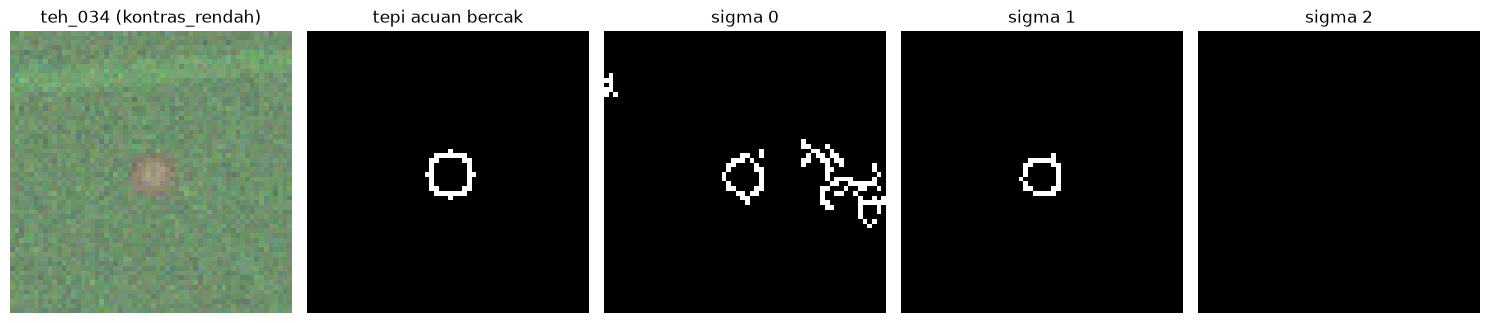

jari-jari bercak terkecil kira-kira 5.1 piksel


In [16]:
d = label[label.nama_file == "teh_034.png"].iloc[0]
img, md, mb = muat(d.nama_file); g = praproses(img, PARAM)[:, :, 2]
n, lab, st, pusat = cv2.connectedComponentsWithStats((mb > 0).astype(np.uint8))
i = 1 + np.argmin(st[1:, cv2.CC_STAT_AREA]); cx, cy = pusat[i].astype(int); r = 30
sl = (slice(max(cy - r, 0), cy + r), slice(max(cx - r, 0), cx + r))
panel = [cv2.cvtColor(img, cv2.COLOR_BGR2RGB)[sl], tepi_acuan(mb)[sl]] + [tepi_canny(g, 30, 90, s)[sl] for s in [0, 1.0, 2.0]]
judul = [f"{d.nama_file[:7]} ({d.kondisi_cahaya})", "tepi acuan bercak", "sigma 0", "sigma 1", "sigma 2"]
plt.figure(figsize=(15, 3.4))
for j, (p_, jd) in enumerate(zip(panel, judul)):
    plt.subplot(1, 5, j + 1); plt.imshow(p_, cmap=None if p_.ndim == 3 else "gray"); plt.title(jd); plt.axis("off")
plt.tight_layout(); simpan("p5_canny_sigma.png"); plt.show()
print("jari-jari bercak terkecil kira-kira", round(np.sqrt(st[i, cv2.CC_STAT_AREA] / np.pi), 1), "piksel")

### Langkah 2.3 Ambang otomatis
**Kode 2.2** Ambang Canny otomatis berbasis median

In [17]:
def canny_otomatis(g, s=0.33):
    # Ambang dari median intensitas: bawah = (1 - s) x median, atas = (1 + s) x median.
    v = np.median(g)
    return cv2.Canny(g, int(max(0, (1 - s) * v)), int(min(255, (1 + s) * v)))

baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
    pra_ = praproses(img, PARAM)
    for kanal, g in [("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)), ("R", pra_[:, :, 2])]:
        baris.append([d.kondisi_cahaya, kanal, "otomatis", skor_tepi(canny_otomatis(g), ac)[2], np.median(g)])
        baris.append([d.kondisi_cahaya, kanal, "tetap 30/90", skor_tepi(tepi_canny(g), ac)[2], np.median(g)])
auto = pd.DataFrame(baris, columns=["kondisi", "kanal", "ambang", "F1", "median"])
print(auto.pivot_table(index=["kanal", "ambang"], columns="kondisi", values="F1").round(3)[URUT])
print(auto.groupby(["kanal", "kondisi"])["median"].mean().round(1).unstack()[URUT])

kondisi            normal  gelap  terang  kontras_rendah  bayangan
kanal ambang                                                      
Gray  otomatis      0.992  0.850   0.980           0.000     0.761
      tetap 30/90   0.952  0.931   0.953           0.000     0.865
R     otomatis      0.993  0.972   0.986           0.850     0.733
      tetap 30/90   0.995  0.982   0.988           0.943     0.998
kondisi  normal  gelap  terang  kontras_rendah  bayangan
kanal                                                   
Gray      195.2  136.6   208.4           162.2     114.4
R         202.5  156.1   218.6           164.0     121.1


**Bukti P2.3:** ambang otomatis (dari median intensitas) dibandingkan dengan besar gradien yang benar-benar ada di tepi daun dan tepi bercak pada citra kontras rendah. `cv2.Canny` memakai Sobel 3 × 3 dengan norma L1 (|Gx| + |Gy|) bila `L2gradient=False`, jadi magnitudo dihitung dengan cara yang sama: tanpa penghalusan untuk ambang otomatis, dan sesudah Gaussian sigma 2 untuk ambang tetap 30/90.

In [18]:
def mag_l1(g):
    g = g.astype(np.float32)
    return np.abs(cv2.Sobel(g, cv2.CV_32F, 1, 0)) + np.abs(cv2.Sobel(g, cv2.CV_32F, 0, 1))

baris = []
for kl, kd, p_, md, mb in pra40:
    if kd != "kontras_rendah":
        continue
    ad, ab = tepi_acuan(md) > 0, tepi_acuan(mb) > 0
    for kanal, g in [("Gray", cv2.cvtColor(p_, cv2.COLOR_BGR2GRAY)), ("R", p_[:, :, 2])]:
        v = np.median(g)
        m0, m2 = mag_l1(g), mag_l1(cv2.GaussianBlur(g, (0, 0), 2.0))
        baris.append([kanal, v, 0.67 * v, 1.33 * v,
                      np.median(m0[ad]), np.median(m0[ab]), np.percentile(m0[md == 0], 95),
                      np.median(m2[ad]), np.median(m2[ab])])
grad = pd.DataFrame(baris, columns=["kanal", "median_intensitas", "lo_otomatis", "hi_otomatis",
                                    "mag_tepi_daun", "mag_tepi_bercak", "mag_latar_p95",
                                    "mag_tepi_daun_s2", "mag_tepi_bercak_s2"])
grad_r = grad.groupby("kanal").mean().round(1)
grad_r.to_csv("../hasil/p5_gradien_kontras_rendah.csv")
grad_r.T

kanal,Gray,R
median_intensitas,162.200000,164.000000
lo_otomatis,108.700000,109.900000
hi_otomatis,215.800000,218.100000
mag_tepi_daun,96.800003,153.500000
mag_tepi_bercak,36.200001,107.000000
mag_latar_p95,35.799999,53.799999
mag_tepi_daun_s2,56.200001,87.500000
mag_tepi_bercak_s2,28.500000,69.400002


**Temuan:**
- Pada kontras rendah, median intensitas tinggi (≈162 Gray, ≈164 R) karena didominasi nampan dan pergeseran +95. Ambang otomatis jadi ≈109/216.
- Magnitudo tepi daun kanal Gray hanya ≈97, di bawah ambang bawah, jadi tidak ada tepi.
- Kanal R ≈154 (di antara kedua ambang); sebagian piksel melewati 216, sehingga tepi daun masih terbentuk.
- Untuk ambang tetap 30/90 sesudah sigma 2: Gray hanya ≈56 (tepi daun) dan ≈29 (tepi bercak), tidak ada piksel kuat; R ≈88 dan ≈69, di sekitar ambang atas.

### Langkah 2.4 Kerjakan sendiri: ambang dari persentil magnitudo
`canny_persentil(g, q, rasio=0.4, sigma=2.0)`: (1) Gaussian, (2) magnitudo Sobel, (3) ambang atas = persentil ke-q magnitudo, ambang bawah = rasio × ambang atas, (4) `cv2.Canny`. Magnitudo dihitung dengan norma L2 (`np.hypot`), jadi `cv2.Canny` juga dipanggil dengan `L2gradient=True` supaya ambang dan gradien yang dibandingkan memakai satuan yang sama.

In [19]:
def canny_persentil(g, q, rasio=0.4, sigma=2.0):
    gb = cv2.GaussianBlur(g, (0, 0), sigma) if sigma > 0 else g          # (1)
    gf = gb.astype(np.float32)
    mag = np.hypot(cv2.Sobel(gf, cv2.CV_32F, 1, 0), cv2.Sobel(gf, cv2.CV_32F, 0, 1))  # (2)
    hi = float(np.percentile(mag, q)); lo = rasio * hi                     # (3)
    return cv2.Canny(gb, lo, hi, L2gradient=True)                          # (4)

baris = []
for kl, kd, p_, md, mb in pra40:
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
    for kanal, g in [("Gray", cv2.cvtColor(p_, cv2.COLOR_BGR2GRAY)), ("R", p_[:, :, 2])]:
        baris.append([kd, kanal, "median (Kode 2.2)", skor_tepi(canny_otomatis(g), ac)[2]])
        baris.append([kd, kanal, "tetap 30/90", skor_tepi(tepi_canny(g), ac)[2]])
        for q in [90, 95, 98]:
            baris.append([kd, kanal, f"persentil q={q}", skor_tepi(canny_persentil(g, q), ac)[2]])
pers = pd.DataFrame(baris, columns=["kondisi", "kanal", "ambang", "F1"])
tabel_pers = pers.pivot_table(index=["kanal", "ambang"], columns="kondisi", values="F1")[URUT]
tabel_pers["rerata"] = tabel_pers.mean(axis=1)
tabel_pers["simp_baku_antar_kondisi"] = tabel_pers[URUT].std(axis=1)
tabel_pers = tabel_pers.round(3)
tabel_pers.to_csv("../hasil/p5_canny_persentil.csv")
tabel_pers

kondisi                  normal  gelap  terang  kontras_rendah  bayangan  rerata  simp_baku_antar_kondisi
kanal ambang                                                                                             
Gray  median (Kode 2.2)   0.992  0.850   0.980           0.000     0.761   0.716                    0.412
      persentil q=90      0.067  0.071   0.063           0.052     0.087   0.068                    0.013
      persentil q=95      0.666  0.662   0.491           0.281     0.539   0.528                    0.158
      persentil q=98      0.960  0.890   0.928           0.833     0.817   0.885                    0.061
      tetap 30/90         0.952  0.931   0.953           0.000     0.865   0.740                    0.415
R     median (Kode 2.2)   0.993  0.972   0.986           0.850     0.733   0.907                    0.113
      persentil q=90      0.070  0.074   0.076           0.059     0.089   0.074                    0.011
      persentil q=95      0.648  0.537   0.396           0.234     0.460   0.455                    0.155
      persentil q=98      0.996  0.986   0.996           0.990     0.998   0.993                    0.005
      tetap 30/90         0.995  0.982   0.988           0.943     0.998   0.981                    0.022

**Temuan:** q = 98 paling baik dan paling stabil. Kanal R F1 0,993 dengan simpangan baku antarkondisi 0,005 (ambang median 0,113; tetap 30/90 0,022), termasuk kontras rendah 0,990. q = 90 dan 95 terlalu rendah, sehingga ambang atas jatuh di wilayah derau.

**Bukti P2.4: q dan proporsi piksel tepi.** Sapuan q yang lebih rapat pada kedua kanal, lalu dibandingkan dengan porsi piksel citra yang berada dalam pita ±2 piksel dari tepi acuan (wilayah yang boleh berisi tepi).

In [20]:
baris = []
for kl, kd, p_, md, mb in pra40:
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
    pita = cv2.dilate(ac, np.ones((5, 5), np.uint8)) > 0
    for kanal, g in [("Gray", cv2.cvtColor(p_, cv2.COLOR_BGR2GRAY)), ("R", p_[:, :, 2])]:
        for q in [85, 90, 93, 95, 96, 97, 98, 99]:
            e = canny_persentil(g, q)
            baris.append([kanal, q, *skor_tepi(e, ac), 100 * (e > 0).mean(), 100 * pita.mean(), 100 * (ac > 0).mean()])
qsw = pd.DataFrame(baris, columns=["kanal", "q", "P", "R", "F1", "persen_piksel_tepi_hasil", "persen_pita_acuan", "persen_tepi_acuan"])
q_ring = qsw.groupby(["kanal", "q"]).mean().round(3)
q_ring.to_csv("../hasil/p5_q_sweep.csv")
q_ring

P      R     F1  persen_piksel_tepi_hasil  persen_pita_acuan  persen_tepi_acuan
kanal q                                                                                      
Gray  85  0.026  0.955  0.050                    18.787              2.798              0.563
      90  0.035  0.955  0.068                    14.180              2.798              0.563
      93  0.126  0.954  0.204                     7.122              2.798              0.563
      95  0.405  0.953  0.528                     2.110              2.798              0.563
      96  0.565  0.952  0.696                     0.930              2.798              0.563
      97  0.640  0.952  0.761                     0.744              2.798              0.563
      98  0.849  0.949  0.885                     0.571              2.798              0.563
      99  0.970  0.888  0.925                     0.458              2.798              0.563
R     85  0.028  0.997  0.055                    18.120              2.798              0.563
      90  0.038  0.997  0.074                    13.670              2.798              0.563
      93  0.080  0.997  0.143                     8.509              2.798              0.563
      95  0.354  0.996  0.455                     3.358              2.798              0.563
      96  0.598  0.996  0.685                     1.511              2.798              0.563
      97  0.855  0.995  0.904                     0.636              2.798              0.563
      98  0.992  0.994  0.993                     0.500              2.798              0.563
      99  0.995  0.939  0.965                     0.471              2.798              0.563

**Temuan:** tepi acuan hanya 0,56% piksel citra, dan pita ±2 piksel di sekitarnya 2,8%. Sesudah Gaussian sigma 2, punggung gradien selebar beberapa piksel, jadi sekitar 2–3% piksel bermagnitudo tinggi.
- q = 98 (2% teratas) menaruh ambang atas tepat di punggung itu.
- q ≤ 95 memasukkan derau: piksel tepi hasil 3–18%, padahal acuannya 0,56%.
- q = 99 terlalu ketat: recall turun ke 0,939.

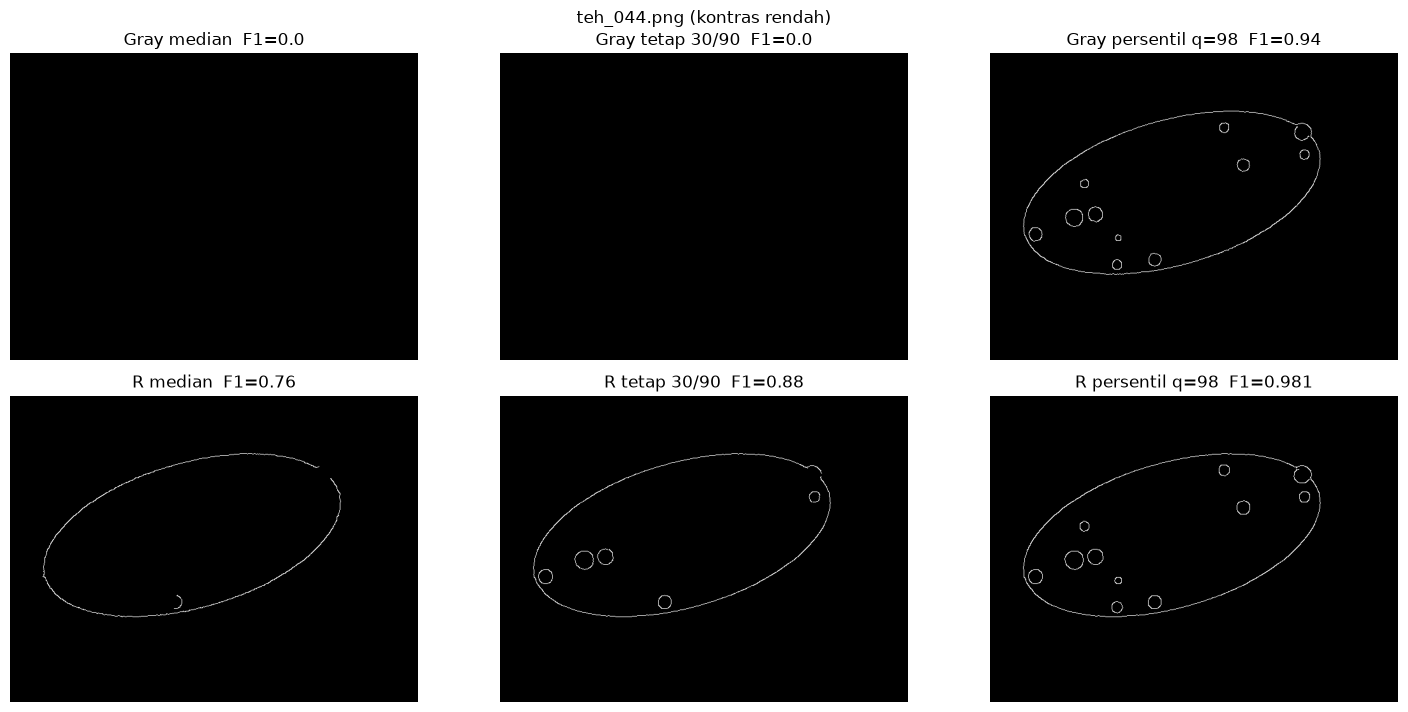

In [21]:
# Panel: satu citra kontras rendah, ambang median vs tetap vs persentil, kanal Gray dan R
d = label[(label.kelas == "berat") & (label.kondisi_cahaya == "kontras_rendah")].iloc[0]
img, md, mb = muat(d.nama_file); p_ = praproses(img, PARAM)
ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
panel, judul = [], []
for kanal, g in [("Gray", cv2.cvtColor(p_, cv2.COLOR_BGR2GRAY)), ("R", p_[:, :, 2])]:
    for nm, e in [("median", canny_otomatis(g)), ("tetap 30/90", tepi_canny(g)), ("persentil q=98", canny_persentil(g, 98))]:
        panel.append(e); judul.append(f"{kanal} {nm}  F1={skor_tepi(e, ac)[2]}")
tampil(panel, judul, baris=2, ukuran=(15, 7))
plt.suptitle(f"{d.nama_file} (kontras rendah)", y=1.01)
simpan("p5_ambang_otomatis.png"); plt.show()

### Langkah 2.5 Tepi pada daun sehat
**Kode 2.3** Tepi palsu di bagian dalam daun sehat

kanal            Gray    R
kondisi                   
normal            0.0  0.0
gelap           204.2  0.0
terang            0.0  0.0
kontras_rendah    0.0  0.0
bayangan        498.5  0.0


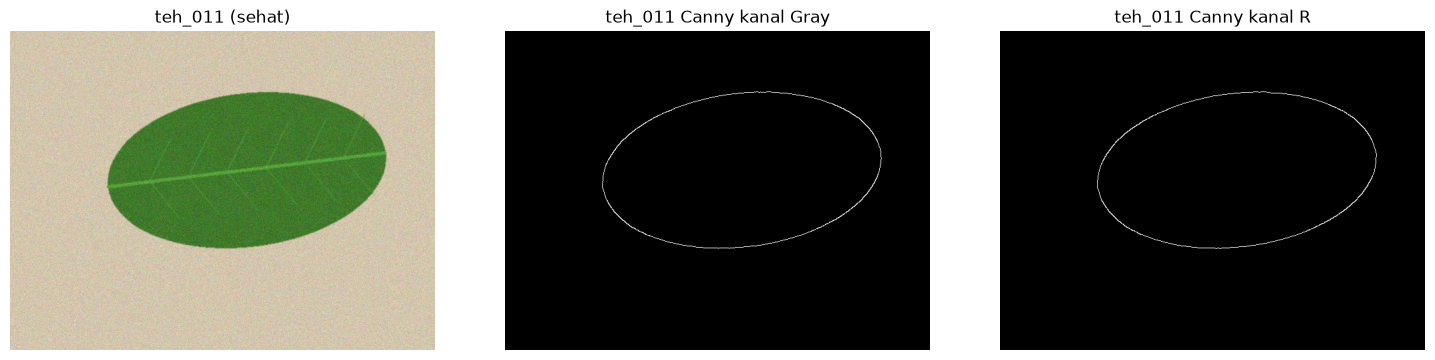

In [22]:
baris, panel, judul = [], [], []
for _, d in label[label.kelas == "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    dalam = cv2.erode(md, np.ones((7, 7), np.uint8)) > 0     # bagian dalam daun
    for kanal, g in [("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)), ("R", pra_[:, :, 2])]:
        e = tepi_canny(g)
        baris.append([d.kondisi_cahaya, kanal, int(((e > 0) & dalam).sum())])
        if d.nama_file == "teh_011.png":
            panel.append(e); judul.append(f"teh_011 Canny kanal {kanal}")
sehat = pd.DataFrame(baris, columns=["kondisi", "kanal", "piksel_tepi_di_dalam_daun"])
print(sehat.pivot_table(index="kondisi", columns="kanal", values="piksel_tepi_di_dalam_daun").round(1).loc[URUT])
tampil([muat("teh_011.png")[0]] + panel, ["teh_011 (sehat)"] + judul, ukuran=(15, 3.6))
simpan("p5_tepi_sehat.png"); plt.show()

**Bukti P2.5: kontras tulang daun per kanal.** Mask tulang daun diambil dari citra `bersih/` (sebelum gangguan cahaya dan derau): piksel daun di luar bercak yang kanal G-nya > 1,15 × median G daun. Pada pembuat dataset, tulang daun digambar dengan warna `hijau × 1,35`, jadi selisihnya sebanding dengan nilai kanal itu sendiri.

In [23]:
bersih = baca("../data/sintetis/bersih/teh_011.png")
print("BGR helai daun (bersih, teh_011):", np.median(bersih[(muat("teh_011.png")[1] > 0)], axis=0))
baris = []
for _, d in label[label.kelas == "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    bersih = baca(f"../data/sintetis/bersih/{d.nama_file}")
    dalam = cv2.erode(md, np.ones((15, 15), np.uint8)) > 0       # jauhi batas daun
    G = bersih[:, :, 1].astype(float)
    tulang = dalam & (G > 1.15 * np.median(G[dalam]))
    helai = dalam & ~cv2.dilate(tulang.astype(np.uint8), np.ones((7, 7), np.uint8)).astype(bool)
    p_ = praproses(img, PARAM)
    for kanal, g in [("Gray", cv2.cvtColor(p_, cv2.COLOR_BGR2GRAY)), ("R", p_[:, :, 2])]:
        gf = g.astype(float)
        mg = mag_l1(cv2.GaussianBlur(g, (0, 0), 2.0))
        e = tepi_canny(g)
        baris.append([d.kondisi_cahaya, kanal, gf[tulang].mean() - gf[helai].mean(),
                      np.median(mg[tulang]), np.percentile(mg[tulang], 99), np.percentile(mg[helai], 99),
                      int(((e > 0) & tulang).sum())])
tl = pd.DataFrame(baris, columns=["kondisi", "kanal", "kontras_tulang", "mag_tulang_median", "mag_tulang_p99",
                                  "mag_helai_p99", "piksel_canny_di_tulang"])
tl_r = tl.pivot_table(index="kondisi", columns="kanal",
                      values=["kontras_tulang", "mag_tulang_p99", "mag_helai_p99", "piksel_canny_di_tulang"]).round(1).loc[URUT]
tl_r.to_csv("../hasil/p5_tulang_daun.csv")
print(tl_r)

BGR helai daun (bersih, teh_011): [ 43. 122.  64.]
               kontras_tulang       mag_helai_p99       mag_tulang_p99       piksel_canny_di_tulang     
kanal                    Gray     R          Gray     R           Gray     R                   Gray    R
kondisi                                                                                                 
normal                   25.8  16.5          13.5  15.5           55.5  39.5                    0.0  0.0
gelap                    30.8   8.8          14.0  13.5           68.0  26.0                   30.2  0.0
terang                   22.4  16.0          14.0  15.5           52.0  40.0                    0.0  0.0
kontras_rendah            9.0   5.0          11.5  16.5           25.0  21.0                    0.0  0.0
bayangan                 31.3  17.9          19.5  16.0           75.0  46.0                   65.8  0.0


**Temuan:** tepi palsu di dalam daun sehat hanya muncul di kanal Gray (gelap 204, bayangan 499 piksel), sedangkan kanal R 0.
- Tulang daun digambar sebagai `hijau × 1,35` pada daun ber-BGR ≈ (43, 122, 64). Selisihnya ≈43 pada G, tetapi hanya ≈22 pada R.
- Gray mengambil 58,7% dari G, sehingga kontras tulang daun di Gray 1,4–3,5× kanal R.
- Pada kondisi gelap (gamma 2,0 dari pembuat dataset) dan bayangan (CLAHE pada praproses), kontras tulang di Gray naik ke ≈31. Magnitudonya cukup untuk melewati ambang Canny.

### Langkah 2.6 Bukti untuk Tabel 8 (keputusan)
**(a) Batas daun:** tepi Canny dinilai hanya terhadap tepi daun acuan, dibandingkan dengan batas dari mask daun hasil segmentasi sederhana (`mask_daun_awal`, Otsu kanal S).
**(b) Batas bercak:** recall tepi bercak dari Tabel 7.
**(c) Mengisi wilayah bercak:** kontur tertutup dari tepi Canny (batas daun dibuang) diisi, lalu dibandingkan dengan mask bercak acuan (IoU dan persen bercak). Pembandingnya `bercak_awal` (ambang median + 4 MAD, belum dibersihkan).
**(d) Fitur bentuk:** jumlah bercak yang terbentuk sebagai kontur tertutup dibandingkan dengan jumlah bercak acuan.

In [24]:
def isi_dari_canny(g, m_daun):
    e = tepi_canny(g)                                            # Canny 30/90, sigma 2
    e = cv2.bitwise_and(e, cv2.erode(m_daun, np.ones((9, 9), np.uint8)))   # buang batas daun
    kontur, _ = cv2.findContours(e, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    isi = np.zeros_like(e)
    cv2.drawContours(isi, kontur, -1, 255, -1)                   # isi bagian dalam kontur
    return isi

def n_komp(m, luas_min=20):
    n, _, st, _ = cv2.connectedComponentsWithStats((m > 0).astype(np.uint8))
    return int((st[1:, cv2.CC_STAT_AREA] >= luas_min).sum())

def daun_dari_canny(g):
    # kontur luar terbesar dari tepi Canny diisi -> wilayah daun
    kontur, _ = cv2.findContours(tepi_canny(g), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    isi = np.zeros(g.shape, np.uint8)
    cv2.drawContours(isi, [max(kontur, key=cv2.contourArea)], -1, 255, -1)
    return isi

ELIPS5 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
baris = []
for kl, kd, p_, md, mb in pra40:
    g = p_[:, :, 2]
    m_daun = mask_daun_awal(p_)
    e = tepi_canny(g)
    isi = isi_dari_canny(g, m_daun)
    b0 = bercak_awal(p_, m_daun, kanal=2, k=4.0)
    b0_open = cv2.morphologyEx(b0, cv2.MORPH_OPEN, ELIPS5)        # pratinjau pembersihan P6
    luas_daun = (md > 0).sum()
    baris.append([kl, kd,
                  skor_tepi(e, tepi_acuan(md))[1], iou(daun_dari_canny(g), md), iou(m_daun, md),
                  iou(isi, mb), iou(b0, mb), iou(b0_open, mb),
                  100 * (mb > 0).sum() / luas_daun, 100 * (isi > 0).sum() / luas_daun, 100 * (b0_open > 0).sum() / luas_daun,
                  n_komp(mb), n_komp(isi), n_komp(b0_open)])
bukti8 = pd.DataFrame(baris, columns=["kelas", "kondisi", "R_canny_tepi_daun", "IoU_daun_isi_canny", "IoU_mask_daun_awal",
                                      "IoU_isi_canny", "IoU_bercak_awal", "IoU_bercak_awal_open",
                                      "persen_acuan", "persen_isi_canny", "persen_bercak_awal_open",
                                      "n_acuan", "n_isi_canny", "n_bercak_awal_open"])
bukti8.to_csv("../hasil/p5_bukti_tabel8.csv", index=False)
print(bukti8.groupby("kelas").mean(numeric_only=True).round(3).T)
print()
print(bukti8.pivot_table(index="kondisi", values=["IoU_daun_isi_canny", "IoU_mask_daun_awal", "IoU_isi_canny", "IoU_bercak_awal_open"]).round(3).loc[URUT])

kelas                    berat  ringan
R_canny_tepi_daun        0.988   0.999
IoU_daun_isi_canny       0.499   0.647
IoU_mask_daun_awal       0.979   0.994
IoU_isi_canny            0.294   0.282
IoU_bercak_awal          0.660   0.210
IoU_bercak_awal_open     0.837   0.682
persen_acuan             4.998   0.382
persen_isi_canny         1.492   0.124
persen_bercak_awal_open  4.677   0.482
n_acuan                  8.600   1.850
n_isi_canny              6.000   1.000
n_bercak_awal_open       9.500   2.400

                IoU_bercak_awal_open  IoU_daun_isi_canny  IoU_isi_canny  IoU_mask_daun_awal
kondisi                                                                                    
normal                         0.777               0.746          0.561               0.997
gelap                          0.803               0.620          0.204               0.997
terang                         0.837               0.501          0.370               0.995
kontras_rendah                 0

**Pilihan operator untuk batas bercak** (recall tepi bercak per kelas, dan khusus citra kontras rendah).

In [25]:
opsi = {"Canny 30/90 sigma 2": lambda g: tepi_canny(g),
        "Canny 30/90 sigma 1": lambda g: tepi_canny(g, 30, 90, 1.0),
        "persentil q=98 sigma 2": lambda g: canny_persentil(g, 98),
        "persentil q=98 sigma 1": lambda g: canny_persentil(g, 98, sigma=1.0)}
baris = []
for kl, kd, p_, md, mb in pra40:
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb)); ab = tepi_acuan(mb)
    for nm, f in opsi.items():
        e = f(p_[:, :, 2])
        baris.append([kl, kd, nm, *skor_tepi(e, ac), skor_tepi(e, ab)[1]])
ob = pd.DataFrame(baris, columns=["kelas", "kondisi", "opsi", "P", "R", "F1", "R_bercak"])
ring_ob = ob.groupby("opsi")[["P", "R", "F1"]].mean()
ring_ob = ring_ob.join(ob.pivot_table(index="opsi", columns="kelas", values="R_bercak").add_prefix("R_bercak_"))
ring_ob["R_bercak_kontras_rendah"] = ob[ob.kondisi == "kontras_rendah"].groupby("opsi")["R_bercak"].mean()
ring_ob = ring_ob.round(3).loc[list(opsi)]
ring_ob.to_csv("../hasil/p5_opsi_batas_bercak.csv")
ring_ob

,P,R,F1,R_bercak_berat,R_bercak_ringan,R_bercak_kontras_rendah
opsi,,,,,,
Canny 30/90 sigma 2,0.987,0.977,0.981,0.907,0.819,0.422
Canny 30/90 sigma 1,0.815,0.995,0.869,0.980,0.967,0.964
persentil q=98 sigma 2,0.992,0.994,0.993,0.975,0.966,0.969
persentil q=98 sigma 1,0.702,0.996,0.770,0.985,0.966,0.981


**Temuan:**
- (a) Batas daun: Canny menemukannya (recall 0,988–0,999), tetapi kontur luarnya tidak selalu tertutup, sehingga isi kontur hanya IoU 0,50–0,65 terhadap mask daun. Mask daun awal (Otsu S) sudah 0,979–0,994.
- (c) Wilayah bercak dari isi kontur Canny: IoU 0,29/0,28 (berat/ringan), kontras rendah 0,005, persen bercak berat 1,49% vs acuan 5,00%. Ambang kanal R + satu opening elips 5 sudah IoU 0,84/0,68 dengan persen 4,68% (pratinjau P6).
- (b) Batas bercak: `canny_persentil` q = 98 sigma 2 terbaik, dengan F1 0,993 dan recall tepi bercak 0,975 (berat), 0,966 (ringan), 0,969 (kontras rendah).

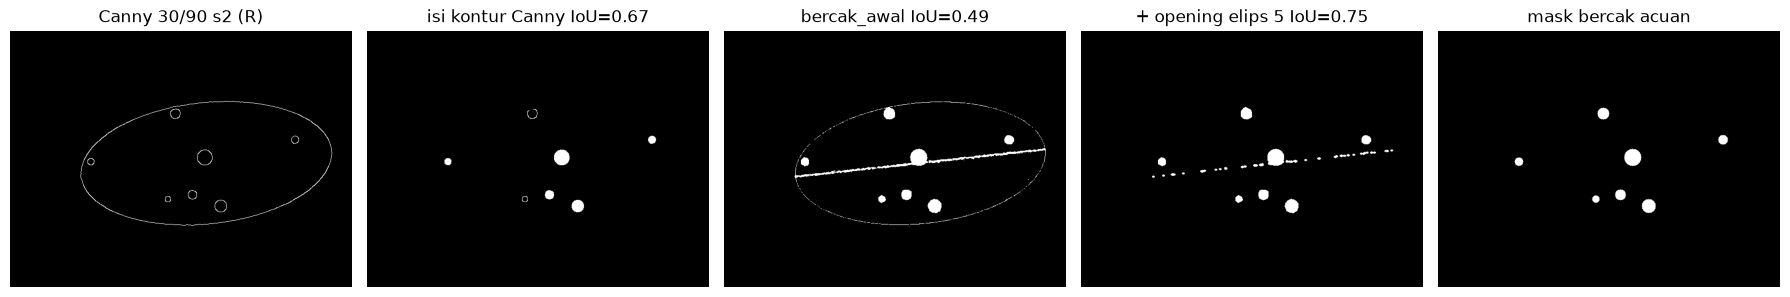

In [26]:
# Panel contoh: tepi Canny, isi kontur Canny, bercak_awal, mask acuan (teh_041)
img, md, mb = muat("teh_041.png"); p_ = praproses(img, PARAM); m_daun = mask_daun_awal(p_)
isi = isi_dari_canny(p_[:, :, 2], m_daun); b0 = bercak_awal(p_, m_daun)
b0o = cv2.morphologyEx(b0, cv2.MORPH_OPEN, ELIPS5)
tampil([tepi_canny(p_[:, :, 2]), isi, b0, b0o, mb],
       ["Canny 30/90 s2 (R)", f"isi kontur Canny IoU={iou(isi, mb):.2f}",
        f"bercak_awal IoU={iou(b0, mb):.2f}", f"+ opening elips 5 IoU={iou(b0o, mb):.2f}", "mask bercak acuan"], ukuran=(18, 3.4))
simpan("p5_isi_kontur.png"); plt.show()

**Waktu proses** (kebutuhan pengguna no. 4). Angka bergantung pada komputer; yang penting perbandingannya.

In [27]:
def waktu(f, ulang=3):
    t0 = time.perf_counter()
    for _ in range(ulang):
        for kl, kd, p_, md, mb in pra40:
            f(p_)
    return 1000 * (time.perf_counter() - t0) / (ulang * len(pra40))
uji = {
    "praproses (dari citra mentah)": lambda p_: praproses(p_, PARAM),
    "Canny 30/90 sigma 2 (R)": lambda p_: tepi_canny(p_[:, :, 2]),
    "canny_persentil q=95 (R)": lambda p_: canny_persentil(p_[:, :, 2], 95),
    "isi kontur Canny": lambda p_: isi_dari_canny(p_[:, :, 2], mask_daun_awal(p_)),
    "mask_daun_awal + bercak_awal": lambda p_: bercak_awal(p_, mask_daun_awal(p_)),
}
for nm, f in uji.items():
    print(f"{nm:32s} {waktu(f):6.2f} ms/citra")

praproses (dari citra mentah)      4.01 ms/citra
Canny 30/90 sigma 2 (R)            0.93 ms/citra
canny_persentil q=95 (R)           8.27 ms/citra
isi kontur Canny                   2.16 ms/citra
mask_daun_awal + bercak_awal       4.49 ms/citra


Di laptop pengujian, Canny butuh ≈0,9 ms per citra, `canny_persentil` ≈8 ms (persentil perlu memilah 307.200 nilai magnitudo), dan ambang bercak ≈4,5 ms. Semuanya cepat. Yang menentukan adalah apakah keluarannya langsung berupa **luas**.

### Tabel 8. Keputusan pemakaian deteksi tepi pada SIMUTEH

| Keperluan | Dipakai? | Operator dan parameter | Bukti |
|---|---|---|---|
| Menemukan batas daun | Tidak (Canny) | Batas daun diambil dari mask daun hasil segmentasi, lalu gradien morfologi (P6) | Recall Canny 0,988–0,999 tetapi isi konturnya IoU 0,50–0,65; mask daun awal IoU 0,979–0,994 |
| Menemukan batas bercak | Ya, sebagai pemeriksa mutu dan penanda visual | `canny_persentil` kanal R, q = 98, rasio 0,4, sigma 2 | F1 0,993; recall tepi bercak ringan 0,966 dan kontras rendah 0,969; simpangan baku antarkondisi 0,005. Canny tetap sigma 2 hanya 0,422 pada kontras rendah |
| Mengisi wilayah bercak (segmentasi) | Tidak | Ambang kanal R (median + k·MAD) lalu morfologi (P6) | Isi kontur Canny IoU 0,29/0,28 (kontras rendah 0,005); ambang + opening IoU 0,84/0,68 |
| Fitur bentuk bercak (P9) | Ya, kontur diambil dari mask bercak, bukan dari tepi | `cv2.findContours` pada mask bercak hasil P6 | Kontur Canny yang tertutup hanya 6,0 dari 8,6 bercak (berat) dan 1,0 dari 1,85 (ringan) |

**Tahap pemakaian:** sesudah segmentasi bercak. Tepi `canny_persentil` dibandingkan dengan kontur mask bercak; bila keduanya tidak berhimpit (F1 rendah), citra ditandai "perlu foto ulang". Luas dan persen bercak tetap dihitung dari mask, bukan dari tepi.

### Langkah 2.7 Checkpoint
Commit seluruh pekerjaan Pertemuan 5, lalu `git tag v0.2-tepi` dan `git push --tags`.